In [1]:
# Name: Saaransh Vats
# Roll Number: 2026B15310304
# Project 05: Telecom Churn & Customer Behaviour

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [5]:
# Checking customer IDs

print("Total Customers:", len(df))

print("Unique Customer IDs:", df['customerID'].nunique())

print("Missing Customer IDs:", df['customerID'].isnull().sum())

print("Duplicate Customer IDs:", df['customerID'].duplicated().sum())

Total Customers: 7043
Unique Customer IDs: 7043
Missing Customer IDs: 0
Duplicate Customer IDs: 0


In [6]:
# Checking categorical columns

cat_cols = df.select_dtypes(include='object').columns

print("Categorical Columns:")

for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

Categorical Columns:

 customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

 gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

 Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

 MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

 InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

 OnlineBackup
OnlineBackup
No                     308

In [7]:
# Checking churn distribution

print("Churn Counts:")

print(df['Churn'].value_counts())

print("\nChurn Percentage:")

print(df['Churn'].value_counts(normalize=True) * 100)

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


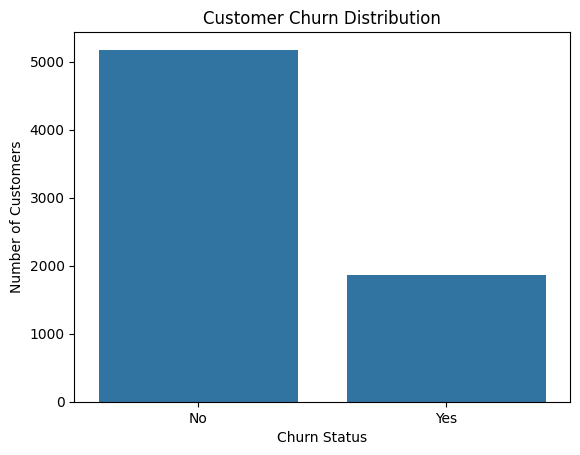

In [8]:
# Visualising churn distribution

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [9]:
# Calculating churn percentages using NumPy

churn_counts = df['Churn'].value_counts()

total = np.sum(churn_counts)

churn_percentages = (churn_counts / total) * 100

print("Total Customers:", total)

print("\nChurn Percentages:")
print(churn_percentages)

Total Customers: 7043

Churn Percentages:
Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


In [10]:
# Creating a copy of the original dataset

df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (7043, 21)
Working Dataset: (7043, 21)


In [11]:
# Checking data types of all columns

print(df_clean.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [12]:
# Converting TotalCharges into numeric format

df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

print("Missing TotalCharges:",
      df_clean['TotalCharges'].isnull().sum())

print(df_clean['TotalCharges'].dtype)

Missing TotalCharges: 11
float64


In [13]:
# Displaying rows with missing TotalCharges

print(df_clean[df_clean['TotalCharges'].isnull()])

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
488   4472-LVYGI  Female              0     Yes        Yes       0   
753   3115-CZMZD    Male              0      No        Yes       0   
936   5709-LVOEQ  Female              0     Yes        Yes       0   
1082  4367-NUYAO    Male              0     Yes        Yes       0   
1340  1371-DWPAZ  Female              0     Yes        Yes       0   
3331  7644-OMVMY    Male              0     Yes        Yes       0   
3826  3213-VVOLG    Male              0     Yes        Yes       0   
4380  2520-SGTTA  Female              0     Yes        Yes       0   
5218  2923-ARZLG    Male              0     Yes        Yes       0   
6670  4075-WKNIU  Female              0     Yes        Yes       0   
6754  2775-SEFEE    Male              0      No        Yes       0   

     PhoneService     MultipleLines InternetService       OnlineSecurity  ...  \
488            No  No phone service             DSL                  Yes  ... 

In [14]:
# Filling missing TotalCharges with zero

df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print("Remaining Missing Values:",
      df_clean['TotalCharges'].isnull().sum())

Remaining Missing Values: 0


In [15]:
# Removing extra spaces from text columns

for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

print("Categorical values cleaned.")

Categorical values cleaned.


In [16]:
# Final data validation

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nDuplicate Customer IDs:",
      df_clean['customerID'].duplicated().sum())

Dataset Shape: (7043, 21)

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     

In [17]:
# Checking available columns for feature engineering

print("Available Columns:")
print(df_clean.columns.tolist())

Available Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [18]:
# Creating tenure-related features

df_clean['TenureYears'] = df_clean['tenure'] / 12

df_clean['TenureGroup'] = pd.cut(
    df_clean['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months',
            '25-48 Months', '49-72 Months']
)

print(df_clean[['tenure', 'TenureYears', 'TenureGroup']].head())

   tenure  TenureYears   TenureGroup
0       1     0.083333   0-12 Months
1      34     2.833333  25-48 Months
2       2     0.166667   0-12 Months
3      45     3.750000  25-48 Months
4       2     0.166667   0-12 Months


In [19]:
# Creating billing-related features

df_clean['AvgMonthlyCharge'] = np.where(
    df_clean['tenure'] > 0,
    df_clean['TotalCharges'] / df_clean['tenure'],
    0
)

df_clean['ChargeDifference'] = (
    df_clean['MonthlyCharges'] -
    df_clean['AvgMonthlyCharge']
)

print(df_clean[
    ['MonthlyCharges', 'TotalCharges',
     'AvgMonthlyCharge', 'ChargeDifference']
].head())

   MonthlyCharges  TotalCharges  AvgMonthlyCharge  ChargeDifference
0           29.85         29.85         29.850000          0.000000
1           56.95       1889.50         55.573529          1.376471
2           53.85        108.15         54.075000         -0.225000
3           42.30       1840.75         40.905556          1.394444
4           70.70        151.65         75.825000         -5.125000


In [20]:
# Creating service-related features

service_cols = [
    'PhoneService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

df_clean['TotalServices'] = (
    df_clean[service_cols] == 'Yes'
).sum(axis=1)

print(df_clean[
    ['customerID', 'TotalServices']
].head())

   customerID  TotalServices
0  7590-VHVEG              1
1  5575-GNVDE              3
2  3668-QPYBK              3
3  7795-CFOCW              3
4  9237-HQITU              1


In [21]:
# Grouping customers based on service adoption

df_clean['ServiceGroup'] = pd.cut(
    df_clean['TotalServices'],
    bins=[-1, 2, 4, 7],
    labels=['Low', 'Medium', 'High']
)

print(df_clean[
    ['TotalServices', 'ServiceGroup']
].head())

   TotalServices ServiceGroup
0              1          Low
1              3       Medium
2              3       Medium
3              3       Medium
4              1          Low


In [22]:
# Checking for support-related columns

support_cols = [
    col for col in df_clean.columns
    if any(word in col.lower()
           for word in ['support', 'ticket', 'complaint', 'call'])
]

print("Available Support Columns:", support_cols)

Available Support Columns: ['TechSupport']


In [23]:
# Checking newly created features

new_features = [
    'TenureYears',
    'TenureGroup',
    'AvgMonthlyCharge',
    'ChargeDifference',
    'TotalServices',
    'ServiceGroup'
]

print(df_clean[new_features].head())

print("\nFeature Information:")
print(df_clean[new_features].info())

   TenureYears   TenureGroup  AvgMonthlyCharge  ChargeDifference  \
0     0.083333   0-12 Months         29.850000          0.000000   
1     2.833333  25-48 Months         55.573529          1.376471   
2     0.166667   0-12 Months         54.075000         -0.225000   
3     3.750000  25-48 Months         40.905556          1.394444   
4     0.166667   0-12 Months         75.825000         -5.125000   

   TotalServices ServiceGroup  
0              1          Low  
1              3       Medium  
2              3       Medium  
3              3       Medium  
4              1          Low  

Feature Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   TenureYears       7043 non-null   float64 
 1   TenureGroup       7043 non-null   category
 2   AvgMonthlyCharge  7043 non-null   float64 
 3   ChargeDifference  7043 non

In [24]:
# Comparing monthly charges of churned and retained customers

churn_yes = df_clean[df_clean['Churn'] == 'Yes']['MonthlyCharges']
churn_no = df_clean[df_clean['Churn'] == 'No']['MonthlyCharges']

print("Customers who left:")
print("Mean:", np.mean(churn_yes))
print("Median:", np.median(churn_yes))
print("Standard Deviation:", np.std(churn_yes))

print("\nCustomers who stayed:")
print("Mean:", np.mean(churn_no))
print("Median:", np.median(churn_no))
print("Standard Deviation:", np.std(churn_no))

Customers who left:
Mean: 74.44133226324237
Median: 79.65
Standard Deviation: 24.659453646367083

Customers who stayed:
Mean: 61.26512369540008
Median: 64.42500000000001
Standard Deviation: 31.089643272938766


In [25]:
# Calculating 95% confidence intervals

def confidence_interval(data):
    mean = np.mean(data)
    se = np.std(data, ddof=1) / np.sqrt(len(data))

    lower = mean - 1.96 * se
    upper = mean + 1.96 * se

    return lower, upper

print("Churn Yes:", confidence_interval(churn_yes))
print("Churn No:", confidence_interval(churn_no))

Churn Yes: (np.float64(73.32305090422292), np.float64(75.55961362226182))
Churn No: (np.float64(60.417895167215555), np.float64(62.1123522235846))


In [26]:
# Calculating the difference between customer segments

mean_yes = np.mean(churn_yes)
mean_no = np.mean(churn_no)

difference = mean_yes - mean_no

print("Average Charges of Churned Customers:", mean_yes)
print("Average Charges of Retained Customers:", mean_no)

print("Difference in Average Charges:", difference)

Average Charges of Churned Customers: 74.44133226324237
Average Charges of Retained Customers: 61.26512369540008
Difference in Average Charges: 13.176208567842295


In [27]:
# Comparing customer tenure distributions

tenure_yes = df_clean[df_clean['Churn'] == 'Yes']['tenure']
tenure_no = df_clean[df_clean['Churn'] == 'No']['tenure']

print("Average Tenure of Churned Customers:",
      np.mean(tenure_yes))

print("Average Tenure of Retained Customers:",
      np.mean(tenure_no))

print("Median Tenure of Churned Customers:",
      np.median(tenure_yes))

print("Median Tenure of Retained Customers:",
      np.median(tenure_no))

Average Tenure of Churned Customers: 17.979133226324237
Average Tenure of Retained Customers: 37.56996521066873
Median Tenure of Churned Customers: 10.0
Median Tenure of Retained Customers: 38.0


In [28]:
# Calculating tenure quantiles

print("25th, 50th and 75th Percentiles:")

print(np.quantile(df_clean['tenure'], [0.25, 0.50, 0.75]))

25th, 50th and 75th Percentiles:
[ 9. 29. 55.]


In [29]:
# Calculating churn rates for different tenure groups

tenure_churn = df_clean.groupby(
    'TenureGroup', observed=False
)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print("Churn Rate by Tenure Group:")
print(tenure_churn)

Churn Rate by Tenure Group:
TenureGroup
0-12 Months     47.438243
13-24 Months    28.710938
25-48 Months    20.388959
49-72 Months     9.513176
Name: Churn, dtype: float64


In [30]:
# Churn percentage by contract type

contract_churn = df_clean.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(contract_churn.round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [31]:
# Churn percentage by payment method

payment_churn = df_clean.groupby('PaymentMethod')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(payment_churn.round(2))

PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


In [32]:
# Churn by internet service

internet_churn = df_clean.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(internet_churn.round(2))

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


In [33]:
# Churn by number of services

service_churn = df_clean.groupby('ServiceGroup', observed=False)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(service_churn.round(2))

ServiceGroup
Low       28.72
Medium    30.91
High      16.33
Name: Churn, dtype: float64


In [34]:
# Churn by contract and payment method

combined_churn = pd.pivot_table(
    df_clean,
    index='Contract',
    columns='PaymentMethod',
    values='Churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
)

print(combined_churn.round(2))

PaymentMethod   Bank transfer (automatic)  Credit card (automatic)  \
Contract                                                             
Month-to-month                      34.13                    32.78   
One year                             9.72                    10.30   
Two year                             3.37                     2.24   

PaymentMethod   Electronic check  Mailed check  
Contract                                        
Month-to-month             53.73         31.58  
One year                   18.44          6.82  
Two year                    7.74          0.79  


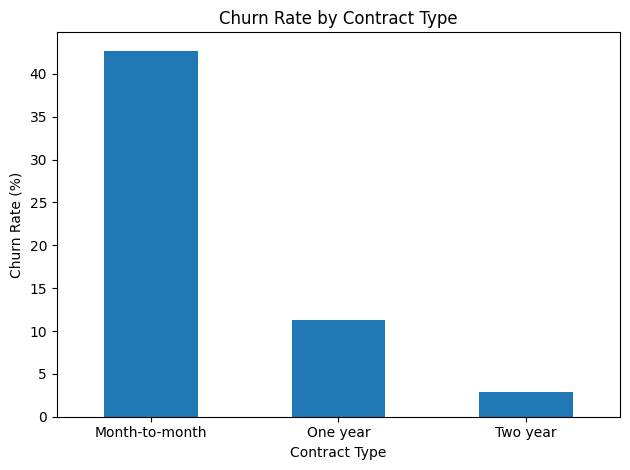

In [35]:
# Contract churn chart

contract_churn.plot(kind='bar')

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

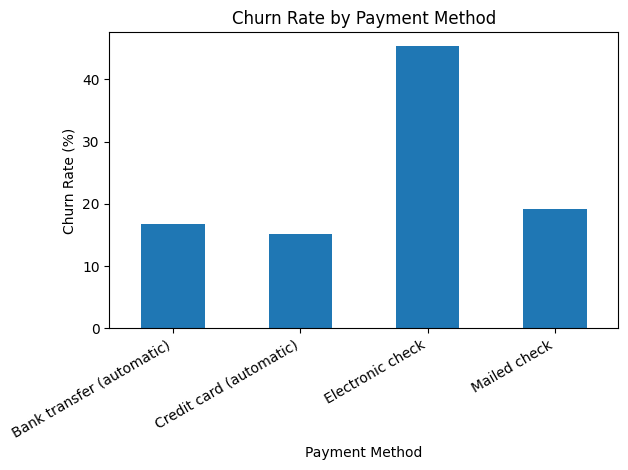

In [36]:
# Payment method churn chart

payment_churn.plot(kind='bar')

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [37]:
# Check all columns

print(df_clean.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureYears', 'TenureGroup', 'AvgMonthlyCharge', 'ChargeDifference', 'TotalServices', 'ServiceGroup']


In [38]:
# Identify columns that should not be used as predictors

leakage_cols = ['customerID', 'Churn']

print("Columns to exclude:")
print(leakage_cols)

print("\nOther columns:")
print(df_clean.drop(columns=leakage_cols).columns.tolist())

Columns to exclude:
['customerID', 'Churn']

Other columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'TenureGroup', 'AvgMonthlyCharge', 'ChargeDifference', 'TotalServices', 'ServiceGroup']


In [39]:
# Compare average monthly charges

print(df_clean.groupby('Churn')['MonthlyCharges'].mean().round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [40]:
# Compare average customer tenure

print(df_clean.groupby('Churn')['tenure'].mean().round(2))

Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


In [41]:
# Correlation between numerical columns and churn

df_clean['ChurnNumeric'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

numeric_data = df_clean.select_dtypes(include=np.number)

correlation = numeric_data.corr()['ChurnNumeric']

print(correlation.sort_values(ascending=False).round(3))

ChurnNumeric        1.000
MonthlyCharges      0.193
AvgMonthlyCharge    0.193
SeniorCitizen       0.151
ChargeDifference   -0.010
TotalServices      -0.086
TotalCharges       -0.198
TenureYears        -0.352
tenure             -0.352
Name: ChurnNumeric, dtype: float64


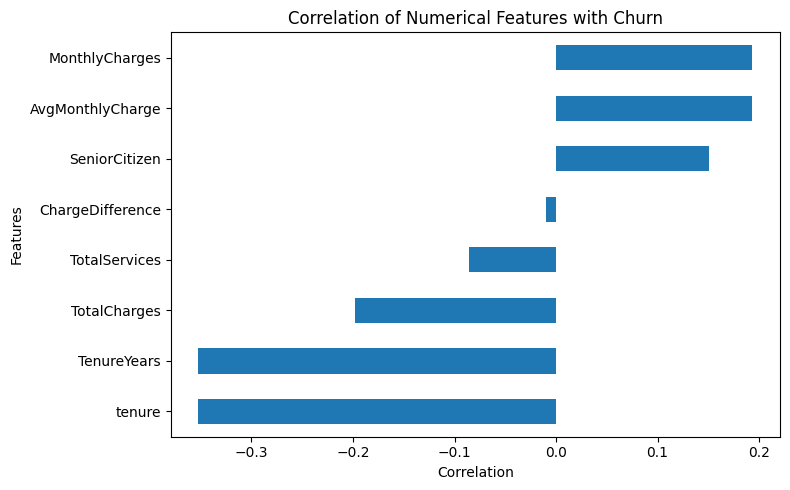

In [42]:
# Correlation chart

correlation.drop('ChurnNumeric').sort_values().plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title('Correlation of Numerical Features with Churn')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [43]:
# Create risk bands

df_clean['RiskScore'] = (
    (df_clean['Contract'] == 'Month-to-month').astype(int) +
    (df_clean['tenure'] <= 12).astype(int) +
    (df_clean['MonthlyCharges'] > 70).astype(int)
)

df_clean['RiskBand'] = pd.cut(
    df_clean['RiskScore'],
    bins=[-1, 1, 2, 3],
    labels=['Low', 'Medium', 'High']
)

print(df_clean[['customerID', 'RiskScore', 'RiskBand']].head())

   customerID  RiskScore RiskBand
0  7590-VHVEG          2   Medium
1  5575-GNVDE          0      Low
2  3668-QPYBK          2   Medium
3  7795-CFOCW          0      Low
4  9237-HQITU          3     High


In [44]:
# Risk band summary

risk_summary = df_clean.groupby('RiskBand', observed=False).agg(
    Customers=('customerID', 'count'),
    ChurnRate=('ChurnNumeric', 'mean'),
    AvgMonthlyCharges=('MonthlyCharges', 'mean')
)

risk_summary['ChurnRate'] *= 100

print(risk_summary.round(2))

          Customers  ChurnRate  AvgMonthlyCharges
RiskBand                                         
Low            3789       8.66              59.66
Medium         2398      39.62              66.28
High            856      69.04              83.08


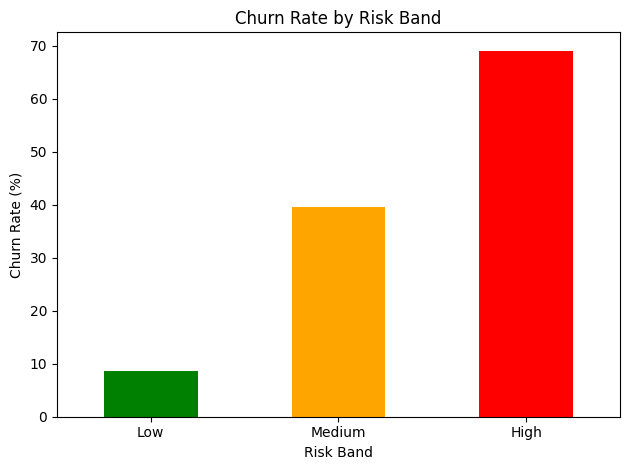

In [45]:
# Churn rate by risk band

risk_summary['ChurnRate'].plot(
    kind='bar',
    color=['green', 'orange', 'red']
)

plt.title('Churn Rate by Risk Band')
plt.xlabel('Risk Band')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
# High-risk customer analysis

high_risk = df_clean[df_clean['RiskBand'] == 'High']

print("High-Risk Customers:", len(high_risk))
print("Average Monthly Charges:", round(high_risk['MonthlyCharges'].mean(), 2))
print("Churn Rate (%):", round(high_risk['ChurnNumeric'].mean() * 100, 2))

High-Risk Customers: 856
Average Monthly Charges: 83.08
Churn Rate (%): 69.04


In [47]:
# Estimate savings from a retention campaign

churn_rate = high_risk['ChurnNumeric'].mean()
expected_churn = len(high_risk) * churn_rate

retention_success = 0.10
customers_saved = expected_churn * retention_success

monthly_revenue_saved = customers_saved * high_risk['MonthlyCharges'].mean()
annual_revenue_saved = monthly_revenue_saved * 12

print("Expected Churned Customers:", round(expected_churn))
print("Customers Retained:", round(customers_saved))
print("Monthly Revenue Retained: $", round(monthly_revenue_saved, 2))
print("Annual Revenue Retained: $", round(annual_revenue_saved, 2))

Expected Churned Customers: 591
Customers Retained: 59
Monthly Revenue Retained: $ 4910.32
Annual Revenue Retained: $ 58923.79


In [48]:
# Save cleaned dataset

df_clean.to_csv('telecom_churn_cleaned.csv', index=False)

print("Final dataset saved successfully!")
print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])

Final dataset saved successfully!
Total Rows: 7043
Total Columns: 30


# Conclusion

In this project, I analysed telecom customer data to understand customer churn.

- I cleaned the dataset and checked missing values and duplicate records.
- I compared churn based on contract type, payment method, monthly charges and tenure.
- I used NumPy and pandas for calculations and analysis.
- I divided customers into low, medium and high-risk groups.
- I estimated the possible impact of a customer retention campaign using a 10% success assumption.

The analysis shows relationships between customer characteristics and churn, but these relationships do not necessarily mean that one factor causes another.